# Drug recommender: targets and baselines

This notebook explains the first stage of the project: **what we ask a drug recommender to predict, how we grade it, and
how well two simple baselines do.** The learned models (M1 ridge, M2 xgboost) come later and must beat these numbers.

**The task.** For each patient, rank the ~116 screened drugs from "most likely to work on this patient's cells" to "least
likely". A good ranking puts drugs the patient was actually sensitive to near the top.

**What's evaluated here.** Everything is **5-fold cross-validation inside Waves1+2** (266 patients). Each fold trains on ~80% of
the patients and grades the rankings on the held-out ~20%. **Waves3+4 (163 patients) are not used anywhere in this
notebook.** They are the final test set, scored once after all modelling choices are frozen.

| Section | Question |
|---|---|
| 1 | What data go in? |
| 2 | What is the target, and why z-scores instead of raw AUC? |
| 3 | What do the baselines recommend, for one real patient? |
| 4 | How well do they do overall? |
| 5 | Which patients do the genomic rules help? |
| 6 | Are the rules biologically right? |
| 7 | What this means for the learned models |

Code lives in `src/` (`targets.py`, `models.py`, `rank_eval.py`, `run_baselines.py`); this notebook calls it.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.targets import load_recommender_data, select_drugs, DrugZScaler, SENSITIVE_Z, MIN_TRAIN
from src.features import alteration_table
from src.models import RandomRanker, PopulationBaseline, GenomicRuleBaseline
from src.rank_eval import summarise
from src.run_baselines import cross_validate, biology_check

MODEL_COL = {"Random": "#8a8984", "B0 population": "#2a78d6", "B1 genomic rules": "#eb6834"}
INK, MUTED, BLUE, RED = "#0b0b0b", "#8a8984", "#2a78d6", "#e34948"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
                     "font.size": 9, "axes.titlesize": 10})

---
## 1. The data

* **Patients:** the 429 who have both RNA-seq and a drug screen. 266 are Waves1+2 (used here), 163 are Waves3+4 (held out).
* **Drugs:** those tested on at least 60 Waves1+2 patients. This depends only on *how many* patients were tested, never on
  their results, so choosing it once up front is safe.
* **Drug response:** AUC of the dose–response curve. **Lower AUC = more cells killed = more sensitive.**
* **Alterations:** every mutation and fusion each patient carries, used by the genomic-rule baseline.

Not every patient was tested on every drug, which is why each patient is graded only on the drugs actually tested on them.

patients: 429 (Waves1+2 266, Waves3+4 163)
drugs tested on >= 60 Waves1+2 patients: 116
Waves1+2 matrix: 74% of patient x drug pairs were tested


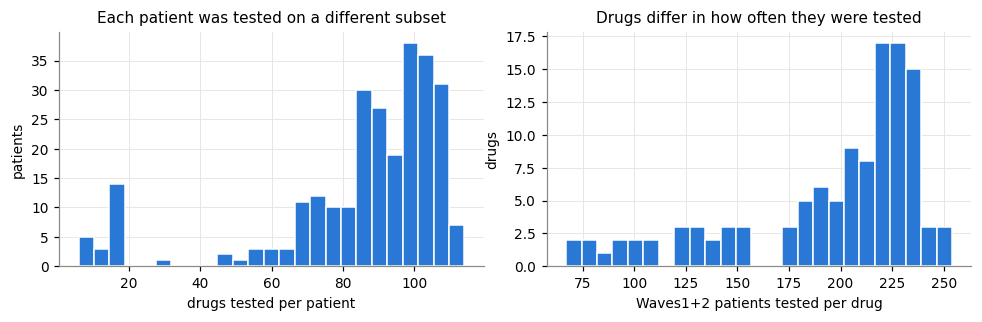

In [2]:
data = load_recommender_data()
drugs = select_drugs(data.auc, data.train)
alts = alteration_table(data.clinical, data.patients)
tr = data.patients[data.train]
A = data.auc.loc[tr, drugs]                      # Waves1+2 patients x drugs, raw AUC

print(f"patients: {len(data.patients)} (Waves1+2 {data.train.sum()}, Waves3+4 {data.test.sum()})")
print(f"drugs tested on >= {MIN_TRAIN} Waves1+2 patients: {len(drugs)}")
print(f"Waves1+2 matrix: {A.notna().mean().mean():.0%} of patient x drug pairs were tested")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(A.notna().sum(axis=1), bins=25, color=BLUE, edgecolor="white")
axes[0].set_xlabel("drugs tested per patient"); axes[0].set_ylabel("patients")
axes[0].set_title("Each patient was tested on a different subset")
axes[1].hist(A.notna().sum(axis=0), bins=25, color=BLUE, edgecolor="white")
axes[1].set_xlabel("Waves1+2 patients tested per drug"); axes[1].set_ylabel("drugs")
axes[1].set_title("Drugs differ in how often they were tested")
plt.tight_layout(); plt.show()

**Reading it.** Most patients were tested on 70–110 of the 116 drugs, but there is a separate cluster of ~20 patients tested on
only 10–18 (probably a smaller panel, run when too few cells were available). Every ranking is graded only on the patient's
tested drugs. Patients with fewer than 10 are skipped (4 patients), which is why the results below report 262 patients rather
than 266. The drugs themselves were each tested on 60–250 Waves1+2 patients.

---
## 2. The target: why z-scores instead of raw AUC

### The problem with raw AUC
Raw AUC mixes three things:

> **AUC = how potent the drug is in general + how sensitive this patient is to everything + this patient's specific response**

Only the last part is personal. The first part dominates: some drugs kill nearly every sample at the doses the lab tested, and
some kill almost none. The left panel shows this for the most and least potent drugs and for venetoclax.

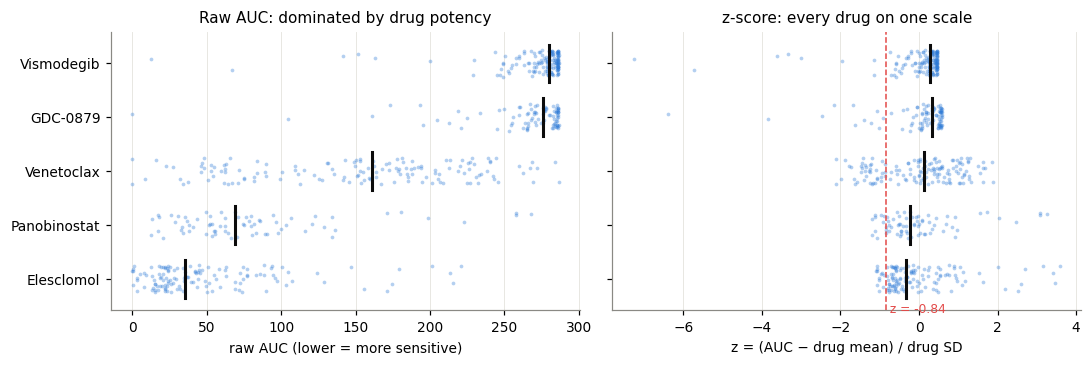

In [3]:
mean_auc = A.mean().sort_values()
show = [mean_auc.index[0], mean_auc.index[1], "Venetoclax", mean_auc.index[-2], mean_auc.index[-1]]
Z = DrugZScaler().fit_transform(A)               # illustration: scaled on all Waves1+2 (CV refits this per fold)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, M, xlabel, title in [(axes[0], A, "raw AUC (lower = more sensitive)", "Raw AUC: dominated by drug potency"),
                             (axes[1], Z, "z = (AUC − drug mean) / drug SD", "z-score: every drug on one scale")]:
    for i, d in enumerate(show):
        v = M[d].dropna()
        ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.25, 0.25, len(v)),
                   s=6, color=BLUE, alpha=0.35, linewidth=0)
        ax.plot([v.median()] * 2, [i - 0.35, i + 0.35], color=INK, lw=2)
    ax.set_yticks(range(len(show)), [d.split(" (")[0] for d in show]); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[1].axvline(SENSITIVE_Z, color=RED, ls="--", lw=1)
axes[1].text(SENSITIVE_Z, -0.45, f" z = {SENSITIVE_Z}", color=RED, fontsize=8, va="top")
plt.tight_layout(); plt.show()

**Reading it.** Each dot is a patient, and the black bar is the median. On the left, the two most potent drugs sit far to the
left for *everyone*, and the weakest drugs sit far right for everyone. Ranking a patient's drugs by raw AUC would mostly
reproduce this potency order, the same for every patient.

On the right, each drug is converted to a **z-score**: how many standard deviations a patient sits from the average patient
*for that drug*. Every drug is now centered on 0, and **z < 0 means "this patient is more sensitive to this drug than typical
AML patients are"**. That's the personal signal the recommender is meant to find.

Notice the weak drugs at the top (vismodegib, GDC-0879): most patients are piled against the maximum AUC, so their z-scores
can't go much above +0.5 but have a long tail to the left. A few patients respond to a drug that does nothing for almost anyone
else, which is exactly the kind of "unusual sensitivity" a personalized recommender should surface.

### The "truly sensitive" label
A patient counts as **truly sensitive** to a drug if **z < −0.84**. On a bell curve, 20% of values fall below −0.84, so the label
means *"among the most sensitive ~20% of patients for this drug."* This is our choice, not the paper's. It's strict enough
that a positive is clearly better than typical, and loose enough that each patient has enough positives (~20 of ~116 drugs)
for the top-5 metric to tell rankings apart.

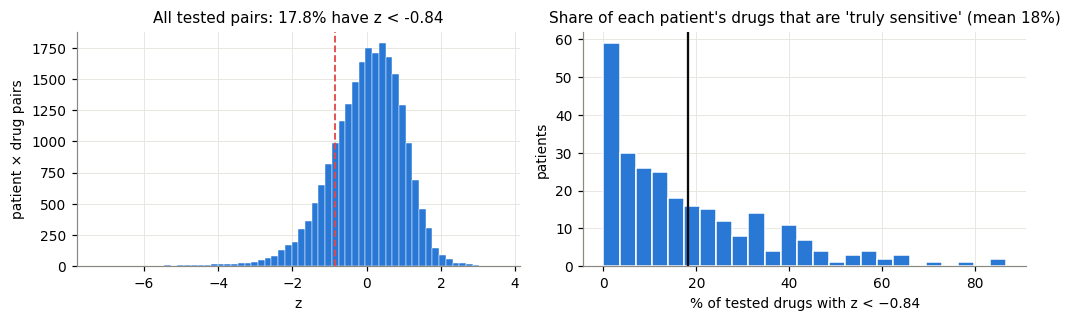

In [4]:
prev = (Z < SENSITIVE_Z).sum(axis=1) / Z.notna().sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
zz = Z.stack()
axes[0].hist(zz, bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
axes[0].axvline(SENSITIVE_Z, color=RED, ls="--", lw=1.2)
axes[0].set_title(f"All tested pairs: {(zz < SENSITIVE_Z).mean():.1%} have z < {SENSITIVE_Z}")
axes[0].set_xlabel("z"); axes[0].set_ylabel("patient × drug pairs")
axes[1].hist(prev * 100, bins=25, color=BLUE, edgecolor="white")
axes[1].axvline(prev.mean() * 100, color=INK, lw=1.5)
axes[1].set_title(f"Share of each patient's drugs that are 'truly sensitive' (mean {prev.mean():.0%})")
axes[1].set_xlabel("% of tested drugs with z < −0.84"); axes[1].set_ylabel("patients")
plt.tight_layout(); plt.show()

**Reading it.**
* **Left:** 18% of pairs fall below the cutoff, close to the 20% a perfect bell curve would give. The shape isn't a perfect bell:
  it has a sharp edge on the right and a long tail to the left. The sharp edge is the assay's ceiling (AUC can't exceed its
  maximum, and many drugs barely work), and the left tail is patients who are far more sensitive than usual.
* **Right:** the share varies a lot by patient. Some patients' cells are broadly sensitive (40%+ of their drugs below the
  cutoff), while about 60 patients are truly sensitive to almost none of their drugs (under 3%). For those patients even a
  perfect ranking can only get one or two hits in a top 5.

That spread matters for grading. A patient with 40% sensitive drugs gets a "good" top 5 by chance much more often than a patient
with 5%. So we always compare a model's precision against that patient's **prevalence**, the precision a random ranking would
get. The difference is called **lift**.

---
## 3. What do the baselines recommend? One real patient

| Model | Recommends first | Uses this patient's data? |
|---|---|---|
| **Random** | random order | No: measures pure chance |
| **B0 population** | drugs with the lowest *average* AUC across training patients. **Same list for everyone.** | No |
| **B1 genomic rules** | drugs that target one of the patient's mutations (e.g. FLT3-ITD → FLT3 inhibitors), then B0's order | Yes: mutations only |

Below is one Waves1+2 patient with FLT3-ITD. To be fair, both baselines are fit on all *other* Waves1+2 patients. The table shows
each baseline's top 5 and how this patient actually responded.

In [5]:
carriers = [p for p in tr if alts.loc[p, "alt.FLT3_ITD"] == 1]
patient = max(carriers, key=lambda p: A.loc[p].notna().sum())      # FLT3-ITD patient with the most drugs tested
others = tr.drop(patient)
z_pt = DrugZScaler().fit(A.loc[others]).transform(A.loc[[patient]]).iloc[0]
tested = z_pt.dropna().index

def top5(model):
    s = model.fit(A.loc[others]).predict(alts.loc[[patient]], list(tested)).iloc[0]
    t = s.sort_values(kind="stable").index[:5]
    return pd.DataFrame({"drug": [d.split(" (")[0] for d in t], "raw AUC": A.loc[patient, t].round(0).to_numpy(),
                         "z": z_pt[t].round(2).to_numpy(), "truly sensitive?": np.where(z_pt[t] < SENSITIVE_Z, "yes", "no")})

b1 = GenomicRuleBaseline().fit(A.loc[others])
flt3_targeted = b1.rule_drugs_["FLT3_ITD"] & set(tested)
print(f"patient {patient}: FLT3-ITD positive, {len(tested)} drugs tested, "
      f"{(z_pt < SENSITIVE_Z).sum()} truly sensitive ({(z_pt < SENSITIVE_Z).mean():.0%} = chance precision)")
print(f"{len(flt3_targeted)} of this patient's tested drugs target FLT3\n")
print("B0 population (same for everyone):"); print(top5(PopulationBaseline()).to_string(index=False))
print("\nB1 genomic rules:"); print(top5(GenomicRuleBaseline()).to_string(index=False))

patient 2371: FLT3-ITD positive, 110 drugs tested, 28 truly sensitive (24% = chance precision)
12 of this patient's tested drugs target FLT3

B0 population (same for everyone):
        drug  raw AUC     z truly sensitive?
Panobinostat    129.0  0.84               no
     SNS-032     51.0 -1.18              yes
   Foretinib     54.0 -1.22              yes
     INK-128    149.0  0.42               no
Flavopiridol    118.0 -0.20               no

B1 genomic rules:
        drug  raw AUC     z truly sensitive?
   Foretinib     54.0 -1.22              yes
JNJ-28312141    126.0 -0.24               no
 Quizartinib     97.0 -1.07              yes
   Dovitinib     79.0 -1.32              yes
    Vargetef    135.0 -0.88              yes


**Reading it.** This patient was truly sensitive to 24% of their tested drugs, so a random top 5 would get about 1.2 hits.
* **B0** picks the five drugs with the lowest *average* AUC, the same five for everyone. **2 of 5** were truly sensitive for
  this patient. One of the hits is foretinib, a multi-kinase drug that also hits FLT3, so even B0 partly benefits from this
  patient's FLT3-ITD by luck. The other three (panobinostat, INK-128, flavopiridol) kill most samples, but this patient was
  no more sensitive to them than typical (z near 0 or positive).
* **B1** puts FLT3-targeted drugs first because the patient has FLT3-ITD. **4 of 5** were truly sensitive (z −0.9 to −1.3).
  The miss, JNJ-28312141, is a FLT3 inhibitor this patient responded to only about as well as average. So the rule is
  right on average but not for every drug it promotes.

This is a single patient; section 4 averages over all of them.

---
## 4. Overall results (5-fold cross-validation within Waves1+2)

**Metrics**, each computed per patient over that patient's tested drugs, then averaged:

| Metric | Question it answers | Chance level | Better |
|---|---|---|---|
| **precision@5** | Of the 5 drugs recommended, what fraction was the patient truly sensitive to? | the patient's prevalence (~18%) | higher |
| **lift@5** | precision@5 minus prevalence: how much better than random? | 0 | higher |
| **NDCG@10** | Are the *most* sensitive drugs near the very top? (rewards strongly negative z more) | ~0.22 | higher |
| **regret** | How much worse (in z) is the #1 recommendation than the patient's best drug? | ~2.2 | lower |
| **Spearman (z)** | Does the whole ranking agree with the patient's z-scores? | 0 | higher |
| **Spearman (raw AUC)** | Does the ranking just track drug potency? | 0 | (diagnostic only) |

Error bars are **95% confidence intervals** from a patient-level bootstrap: resample patients with replacement 1,000 times and
see how much the average moves. Two models whose intervals overlap heavily are not clearly different.

In [6]:
res = cross_validate(data, alts, drugs, n_splits=5, seed=0)
S = {name: summarise(pp, n_boot=1000, seed=0) for name, pp in res.items()}
table = pd.concat({n: s["mean"] for n, s in S.items()}, axis=1).round(3)
print(f"patients graded: {len(next(iter(res.values())))}")
table

patients graded: 262


,Random,B0 population,B1 genomic rules
spearman,0.001,0.003,0.024
spearman_raw,-0.010,0.674,0.654
prec@5,0.179,0.188,0.252
prevalence,0.180,0.180,0.180
lift@5,-0.002,0.007,0.072
ndcg@10,0.225,0.245,0.295
regret,2.184,2.344,2.014


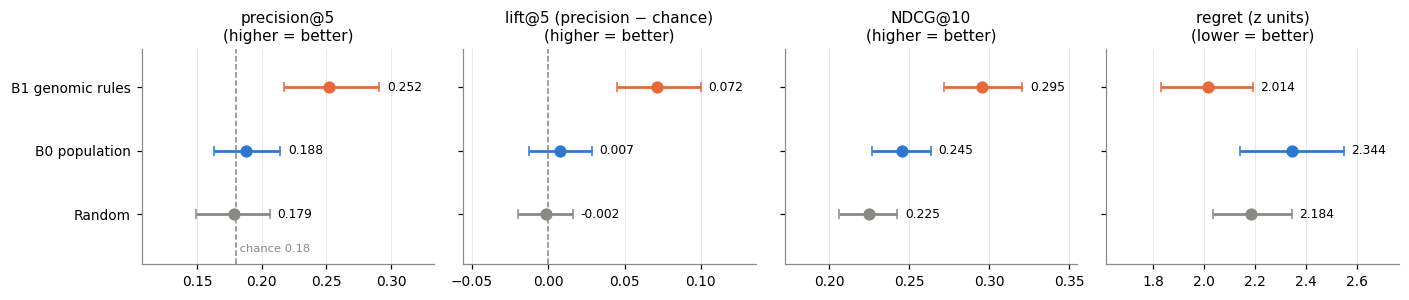

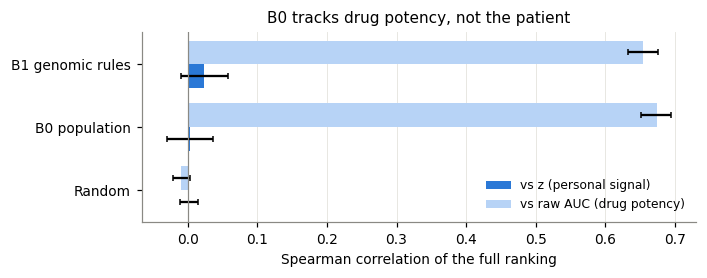

In [7]:
panels = [("prec@5", "precision@5", "higher = better"), ("lift@5", "lift@5 (precision − chance)", "higher = better"),
          ("ndcg@10", "NDCG@10", "higher = better"), ("regret", "regret (z units)", "lower = better")]
names = list(S)
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, (m, title, note) in zip(axes, panels):
    for i, n in enumerate(names):
        mean, lo, hi = S[n].loc[m]
        ax.errorbar(mean, i, xerr=[[mean - lo], [hi - mean]], fmt="o", color=MODEL_COL[n], ms=7, capsize=3, lw=1.8)
        ax.annotate(f"{mean:.3f}", (hi, i), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8)
    if m == "prec@5":
        p = S[names[0]].loc["prevalence", "mean"]
        ax.axvline(p, color=MUTED, ls="--", lw=1); ax.text(p, -0.6, f" chance {p:.2f}", color=MUTED, fontsize=7.5)
    if m == "lift@5":
        ax.axvline(0, color=MUTED, ls="--", lw=1)
    ax.set_title(f"{title}\n({note})"); ax.grid(axis="y", visible=False); ax.set_ylim(-0.8, len(names) - 0.4)
    ax.margins(x=0.3)
axes[0].set_yticks(range(len(names)), names)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 2.6))
w = 0.38
for j, (m, lab, colr) in enumerate([("spearman", "vs z (personal signal)", BLUE), ("spearman_raw", "vs raw AUC (drug potency)", "#b7d3f6")]):
    means = [S[n].loc[m, "mean"] for n in names]
    errs = [[S[n].loc[m, "mean"] - S[n].loc[m, "ci_lo"] for n in names], [S[n].loc[m, "ci_hi"] - S[n].loc[m, "mean"] for n in names]]
    ax.barh(np.arange(len(names)) + (j - 0.5) * w, means, height=w, color=colr, xerr=errs, capsize=2, label=lab)
ax.axvline(0, color=MUTED, lw=0.8); ax.set_yticks(range(len(names)), names); ax.grid(axis="y", visible=False)
ax.set_xlabel("Spearman correlation of the full ranking"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("B0 tracks drug potency, not the patient"); plt.tight_layout(); plt.show()

### Interpretation

**Random is the floor.** Its precision@5 (0.179) equals the average prevalence (0.180), as it should. This confirms the metric is
calibrated: chance gives zero lift.

**B0 is at chance.** Precision@5 0.188 vs 0.179, with heavily overlapping intervals and lift ≈ 0. The second chart shows why:
B0's ranking correlates strongly with **raw AUC** (0.67) but not at all with **z** (0.00). It reliably picks drugs that work on
everyone, and the target deliberately ignores that, because "works on everyone" isn't a personalized recommendation. B0 is
the "no personalization" reference point, not a competitor.

**B1 beats chance clearly.** Precision@5 0.252 (CI 0.22–0.29) against 0.18 at chance: about **7 percentage points of lift**,
with an interval well above 0. NDCG and regret improve too. In practical terms, about 1.3 of B1's 5 recommendations are
drugs the patient was truly sensitive to, vs about 0.9 for random.

**But B1's whole-list Spearman is only 0.02** (interval includes 0). That's expected: B1 moves a handful of targeted drugs to the
top and leaves the other ~100 in B0's order. It improves the **top** of the list, which is what a clinician would look at, but
says little about the rest. So the top-k metrics are the ones that matter for a recommender.

---
## 5. Which patients do the rules help?

B1 can only help patients who carry a lesion it has a rule for. For everyone else it gives exactly B0's list.

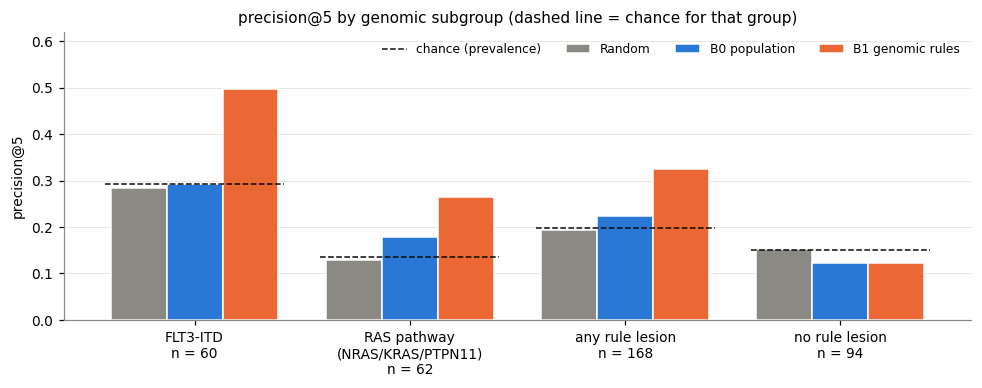

model                            B0 population  B1 genomic rules  Random
group                                                                   
FLT3-ITD                                 0.293             0.497   0.283
RAS pathway\n(NRAS/KRAS/PTPN11)          0.177             0.265   0.129
any rule lesion                          0.224             0.324   0.193
no rule lesion                           0.123             0.123   0.153


In [8]:
rule_alts = [f"alt.{a}" for a in GenomicRuleBaseline().rules if f"alt.{a}" in alts]
groups = {
    "FLT3-ITD": alts["alt.FLT3_ITD"].fillna(0) > 0,
    "RAS pathway\n(NRAS/KRAS/PTPN11)": alts[["alt.NRAS", "alt.KRAS", "alt.PTPN11"]].fillna(0).sum(axis=1) > 0,
    "any rule lesion": alts[rule_alts].fillna(0).sum(axis=1) > 0,
    "no rule lesion": alts[rule_alts].fillna(0).sum(axis=1) == 0,
}
rows = []
for g, mask in groups.items():
    ids = mask.index[mask]
    for n, pp in res.items():
        sub = pp[pp.index.isin(ids)]
        rows.append({"group": g, "model": n, "n": len(sub), "prec@5": sub["prec@5"].mean(), "prevalence": sub["prevalence"].mean()})
sg = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 3.6))
gnames = list(groups); w = 0.26
for j, n in enumerate(names):
    v = sg[sg.model == n].set_index("group").loc[gnames]
    ax.bar(np.arange(len(gnames)) + (j - 1) * w, v["prec@5"], width=w, color=MODEL_COL[n], label=n, edgecolor="white")
prev_g = sg[sg.model == names[0]].set_index("group").loc[gnames]
for i, (pv, nn) in enumerate(zip(prev_g["prevalence"], prev_g["n"])):
    ax.plot([i - 1.6 * w, i + 1.6 * w], [pv, pv], color=INK, ls="--", lw=1)
ax.plot([], [], color=INK, ls="--", lw=1, label="chance (prevalence)")
ax.set_xticks(range(len(gnames)), [f"{g}\nn = {nn}" for g, nn in zip(gnames, prev_g["n"])]); ax.set_ylabel("precision@5"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper right"); ax.set_ylim(0, 0.62)
ax.set_title("precision@5 by genomic subgroup (dashed line = chance for that group)")
plt.tight_layout(); plt.show()
print(sg.pivot(index="group", columns="model", values="prec@5").loc[gnames].round(3).to_string())

**Reading it.**
* **FLT3-ITD patients (n = 60):** B1's precision@5 is about **0.50**, vs 0.29 for B0, which is just the chance level for this group.
  Half of B1's recommendations are drugs these patients were truly sensitive to. This is where most of B1's overall gain
  comes from.
* **RAS-pathway patients:** a smaller gain. MEK inhibitors help, but less consistently.
* **No rule lesion (n = 94, about a third of patients):** B1 is *identical* to B0, and both are slightly **below** random
  (0.12 vs 0.15). The potency-ordered list does a little worse than chance for these patients, probably because they tend
  not to be unusually sensitive to the drugs that work on everyone. **For these patients there is currently no personalized
  signal at all.**

Note that FLT3-ITD patients have a higher chance level (dashed line): they are more drug-sensitive in general, so even random
does better for them. Always compare against the dashed line, not against zero.

---
## 6. Are the rules biologically right?

Before trusting B1, check that the drugs each rule promotes really are more effective in carriers. For each alteration: the
average z of its rule-matched drugs in carriers vs non-carriers (Waves1+2). Negative z = more sensitive.

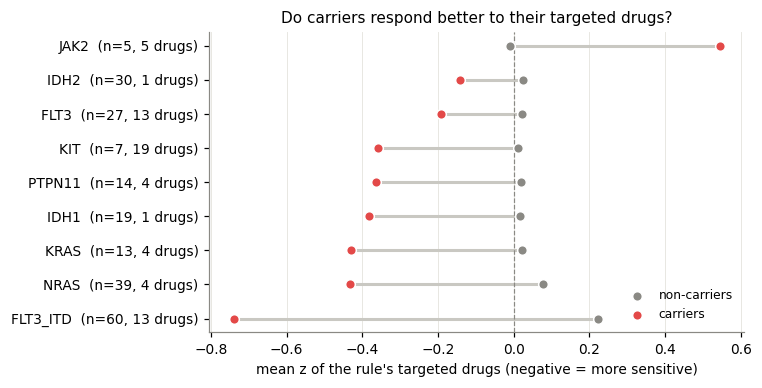

,carriers,targeted drugs,"mean z, carriers","mean z, non-carriers"
alteration,,,,
FLT3_ITD,60,13,-0.740,0.223
NRAS,39,4,-0.432,0.077
KRAS,13,4,-0.431,0.021
IDH1,19,1,-0.382,0.018
PTPN11,14,4,-0.365,0.019
KIT,7,19,-0.358,0.011
FLT3,27,13,-0.193,0.023
IDH2,30,1,-0.142,0.024
JAK2,5,5,0.544,-0.010


In [9]:
bio = biology_check(data, alts, drugs).sort_values("mean z, carriers")
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(bio))
ax.hlines(y, bio["mean z, non-carriers"], bio["mean z, carriers"], color="#c9c8c2", lw=2)
ax.scatter(bio["mean z, non-carriers"], y, color=MUTED, s=40, label="non-carriers", zorder=3, edgecolor="white")
ax.scatter(bio["mean z, carriers"], y, color=RED, s=40, label="carriers", zorder=3, edgecolor="white")
ax.axvline(0, color=MUTED, lw=0.8, ls="--")
ax.set_yticks(y, [f"{a}  (n={c}, {d} drugs)" for a, c, d in zip(bio.index, bio["carriers"], bio["targeted drugs"])])
ax.set_xlabel("mean z of the rule's targeted drugs (negative = more sensitive)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Do carriers respond better to their targeted drugs?")
plt.tight_layout(); plt.show()
bio

**Reading it.** For almost every rule, carriers (red) sit left of non-carriers (gray): their cells were more sensitive to the
targeted drugs, as expected from known pharmacology.
* **FLT3-ITD** has the largest and best-supported gap (−0.74 vs +0.22, 60 carriers).
* **RAS (NRAS/KRAS/PTPN11) → MEK inhibitors** and **IDH1 → its inhibitor** also go the expected way.
* **JAK2 goes the wrong way** (carriers *more resistant*), but there are only 5 carriers, so this is noise-level evidence. With
  few carriers (KIT 7, JAK2 5), any single number is unreliable.

This check uses the same Waves1+2 data the results come from, so it **describes** the training data and doesn't
independently validate the rules. The rules themselves were written from clinical knowledge before looking at these numbers.

---
## 7. What this means for the learned models

**The bar for M1/M2 is B1:** precision@5 ≈ **0.25** (lift ≈ 0.07) in this same cross-validation.

**Where a learned model can add the most: the third of patients with no actionable mutation.** For them, B1 is no better than
chance. The paper's central finding, that drug response depends on tumor **maturation state** (venetoclax works in
progenitor-like tumors and fails in monocytic ones; MEK inhibitors the reverse), is information B1 doesn't use. If M1/M2,
using the cell-type scores, achieve lift in the "no rule lesion" group, that's the project's main result.

**A second test: do learned models also beat B1 for FLT3-ITD patients?** The paper found that FLT3-ITD tumors that are
monocytic respond poorly to FLT3 inhibitors (Fig 3B). A model that combines mutation and maturation state should beat a
rule that treats every FLT3-ITD patient the same.

### Caveats
* All numbers are cross-validation **within Waves1+2**. They are for comparing models while developing them, not final
  results. The final comparison is a single run on Waves3+4.
* The −0.84 cutoff is a choice. NDCG and Spearman don't depend on it; if a conclusion only holds at one cutoff, it's fragile.
* **"Truly sensitive" here means sensitive in a dish.** Whether that predicts clinical response is the question for the
  clinical-validation part of the project (induction response, TCGA survival).